# Paso 7 · NLP aplicado al riesgo de crédito

| | |
|---|---|
| **IDs del enunciado** | IA3.1 (NLP: BERT, embeddings, GPT), IA3.E1 (modelo NLP de predicción de riesgo), R2, F3 |
| **Fase** | F3 · Analizar y modelar (CRISP-DM: *Modeling*) |
| **Historia** | HU-07 · Sprint S6 |
| **Entregable** | este notebook + `Back/models/resultados_nlp.json` + `db/processed/nlp_features.parquet` (caché de inferencias) |

**Objetivo.** Medir cuánta información sobre el impago contiene el texto libre de la solicitud
(`texto_solicitud`) con cuatro enfoques de complejidad creciente: análisis léxico clásico, TF-IDF +
regresión logística, sentimiento con **BERT** y *embeddings* de **sentence-transformers** frente a **GPT-2**.
Después se prueba si el texto agrega valor al modelo tabular servido (**ΔAUC con intervalo bootstrap**).

**Aprendizaje de la unidad (Módulo 2 · Unidad 3, IA3.1).**
- *Conceptual:* el texto se convierte en números de tres maneras: por **conteo** de palabras (bolsa de
  palabras / TF-IDF; interpretable pero sin contexto), por **modelos afinados** para una tarea (BERT de
  sentimiento: un puntaje con significado) y por **representaciones densas** (*embeddings*: vectores donde
  textos parecidos quedan cerca). Un *encoder* entrenado para similitud de oraciones (sentence-transformers)
  y un *decoder* generativo (GPT-2, promedio del último estado oculto) producen vectores distintos para el
  mismo texto. Que un modelo sea más grande no garantiza que sus vectores separen mejor la clase.
- *Práctico:* inferir una sola vez por texto único y **cachear**, comparar todo con la misma validación
  cruzada y el mismo test, y medir el aporte incremental con un intervalo de confianza, no con una sola cifra.
- *Crítico:* conocer **cómo se generaron los datos** orienta la decisión: aquí el texto se sintetizó a partir
  de la probabilidad de impago, y la sección 7 explica por qué la decisión usa el modelo tabular.

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


In [3]:
from credit_risk.notebook import setup

ENTORNO = setup(torch_primero=True)  # torch antes que scikit-learn (WinError 1114 en Windows; ADR-006)
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.10.7',
  'pandas': '2.3.3',
  'numpy': '1.26.4',
  'matplotlib': '3.10.9',
  'seaborn': '0.13.2',
  'scikit-learn': '1.4.2',
  'duckdb': '1.5.6',
  'plotnine': '0.15.8'}}

In [4]:
import time
from collections import Counter

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_validate

from credit_risk import config
from credit_risk import nlp_avanzado as na
from credit_risk.data import cargar_procesados, separar_xy
from credit_risk.features import build_pipeline
from credit_risk.models import calibrado, catalogo, curvas, cv_estratificada, metricas, umbrales_chow
from credit_risk.nlp import build_modelo_texto, normalizar, terminos_asociados, tokens
from credit_risk.notebook import ruta
from credit_risk.reporting import PALETA, SERIE, figura_front
from credit_risk.schemas_resultados import FilaModelo, Metricas, ResultadosNLP, guardar_resultados

train, test = cargar_procesados()
X_tr, y_tr = separar_xy(train)
X_te, y_te = separar_xy(test)
if FAST:  # prueba de humo: submuestra
    X_tr, y_tr = X_tr.iloc[:2000].reset_index(drop=True), y_tr[:2000]
    X_te, y_te = X_te.iloc[:800].reset_index(drop=True), y_te[:800]
TXT = config.TEXT_COL
UMBRAL = umbrales_chow().bayes
CV = cv_estratificada(3 if FAST else config.CV_FOLDS)
print(f"train: {len(X_tr):,} solicitudes · tasa de impago {y_tr.mean():.2%}")
print(f"test : {len(X_te):,} solicitudes · tasa de impago {y_te.mean():.2%}")
print(f"Umbral para métricas de clasificación: {UMBRAL:.2f} · validación cruzada de {CV.get_n_splits()} particiones")

train: 9,600 solicitudes · tasa de impago 35.56%
test : 2,400 solicitudes · tasa de impago 35.58%
Umbral para métricas de clasificación: 0.25 · validación cruzada de 5 particiones


## 1. Análisis de texto clásico

**Limpieza** (`credit_risk.nlp`): `normalizar` pasa a minúsculas y quita tildes (el marcador `Sin texto` de
la limpieza del paso 3 queda como cadena vacía); `tokens` extrae palabras alfabéticas y quita las
*stopwords* en español (`STOPWORDS_ES`, que además incluye palabras de plantilla sin contenido como
*solicito*, *necesito* o *credito*).

In [5]:
ejemplos = X_tr[TXT].drop_duplicates().head(3)
with pd.option_context("display.max_colwidth", 160):
    display(pd.DataFrame({"original": ejemplos.to_numpy(),
                          "tokens sin stopwords": [" · ".join(tokens(t)) for t in ejemplos]}))

,original,tokens sin stopwords
0,Solicito este credito para invertir en mi negocio. Mis gastos han superado mis ingresos en los ultimos meses.,invertir · negocio · gastos · superado · ingresos · ultimos · meses
1,Pido este credito con el fin de capital de trabajo para mi emprendimiento. He cumplido puntualmente con todas mis obligaciones anteriores.,pido · fin · capital · trabajo · emprendimiento · cumplido · puntualmente · todas · obligaciones · anteriores
2,Solicito este credito para una inversion personal. Vengo de una reduccion de ingresos y estoy reorganizando mis finanzas. Espero una respuesta favorable.,inversion · personal · vengo · reduccion · ingresos · estoy · reorganizando · finanzas · espero · respuesta · favorable


**Cuántos textos distintos hay.** Consulta con **DuckDB** (SQL en proceso sobre el DataFrame de pandas).

In [6]:
textos = pd.DataFrame({"texto": X_tr[TXT].map(normalizar), "impago": y_tr})
textos["n_tokens"] = textos["texto"].map(lambda t: len(tokens(t, quitar_stopwords=False)))
resumen_textos = duckdb.sql("""
    SELECT COUNT(*)                                       AS solicitudes,
           COUNT(DISTINCT texto)                          AS textos_unicos,
           SUM(CASE WHEN texto = '' THEN 1 ELSE 0 END)    AS sin_texto,
           ROUND(AVG(n_tokens), 1)                        AS palabras_promedio,
           MAX(n_tokens)                                  AS palabras_max
    FROM textos
""").df()
repetidos = duckdb.sql("""
    SELECT texto, COUNT(*) AS veces, ROUND(AVG(impago), 3) AS tasa_impago
    FROM textos WHERE texto <> ''
    GROUP BY texto ORDER BY veces DESC, texto LIMIT 5
""").df()
display(resumen_textos)
with pd.option_context("display.max_colwidth", 150):
    display(repetidos)

,solicitudes,textos_unicos,sin_texto,palabras_promedio,palabras_max
0,9600,4023,192.0000,19.3000,31


,texto,veces,tasa_impago
0,requiero el prestamo para un proyecto personal. tengo un empleo estable desde hace varios anios.,17,0.1760
1,pido este credito con el fin de cubrir gastos personales. tengo un empleo estable desde hace varios anios.,15,0.2670
2,estoy interesado en un credito para un proyecto personal. tengo un empleo estable desde hace varios anios.,14,0.2140
3,necesito el prestamo para un proyecto personal. mi situacion financiera es solida y organizada.,14,0.3570
4,quisiera acceder a financiacion para gastos varios del hogar. cuento con ingresos estables y buen historial de pago.,14,0.2140


### 1.1 Frecuencias y n-gramas

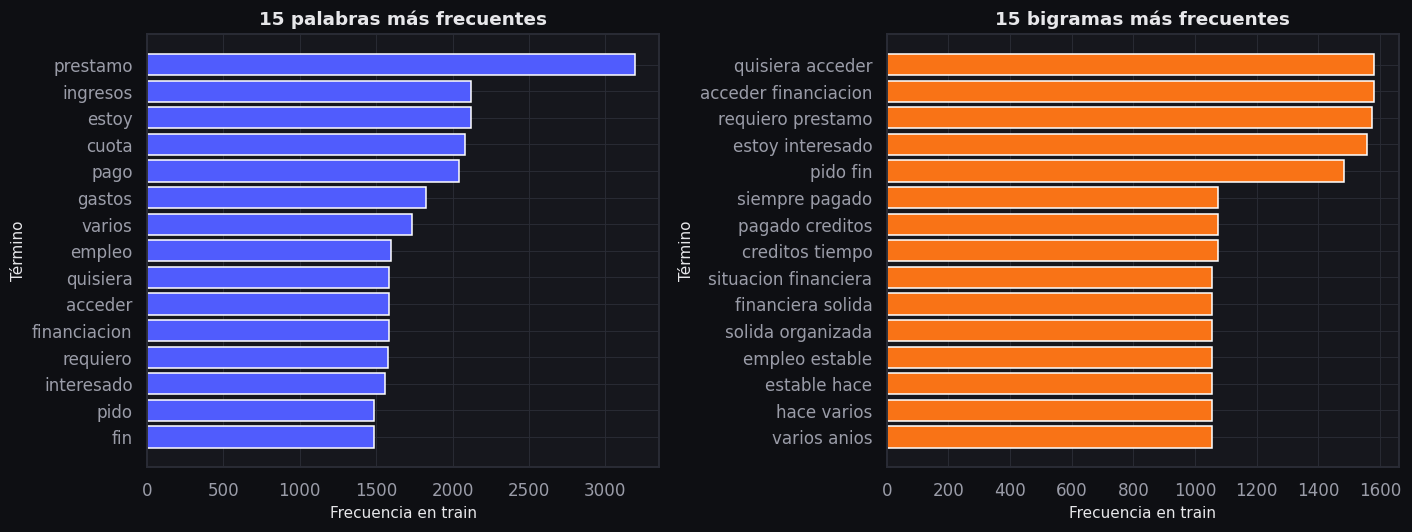

,trigrama,frecuencia
0,quisiera acceder financiacion,1582
1,siempre pagado creditos,1075
2,pagado creditos tiempo,1075
3,situacion financiera solida,1055
4,financiera solida organizada,1055
5,empleo estable hace,1054
6,estable hace varios,1054
7,hace varios anios,1054
8,cuento ingresos estables,1041
9,ingresos estables buen,1041


In [7]:
toks = [tokens(t) for t in X_tr[TXT]]
uni = Counter(w for ts in toks for w in ts).most_common(15)
bi = Counter(" ".join(p) for ts in toks for p in zip(ts, ts[1:])).most_common(15)
tri = Counter(" ".join(p) for ts in toks for p in zip(ts, ts[1:], ts[2:])).most_common(10)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, datos, titulo, color in [(ax[0], uni, "15 palabras más frecuentes", SERIE[0]),
                                (ax[1], bi, "15 bigramas más frecuentes", SERIE[1])]:
    etiquetas, conteos = zip(*datos[::-1])
    a.barh(etiquetas, conteos, color=color)
    a.set(title=titulo, xlabel="Frecuencia en train", ylabel="Término")
plt.tight_layout()
plt.show()
for datos, titulo, clave in [(uni, "Palabras más frecuentes", "frecuencia_unigramas"),
                             (bi, "Bigramas más frecuentes", "frecuencia_bigramas")]:
    figura_front("barras_h", titulo, {"categorias": [d[0] for d in datos],
                                      "series": [{"nombre": "Frecuencia", "valores": [int(d[1]) for d in datos]}]},
                 ejes={"x": "Frecuencia en train", "y": "Término"}, clave=clave, opciones={"formato_x": "num"})
pd.DataFrame(tri, columns=["trigrama", "frecuencia"])

**Interpretación.** El vocabulario es pequeño y se repite: las palabras y bigramas más frecuentes son
fragmentos fijos de plantilla. Varios bigramas tienen **exactamente el mismo conteo** (*quisiera acceder* y
*acceder financiacion*: 1.582) porque salen de la misma frase de apertura, y los trigramas más frecuentes
son frases de cierre completas (*siempre pagado creditos*, *situacion financiera solida*). Con 4.023
textos distintos en 9.600 solicitudes de train, es el patrón típico de un texto sintético: el análisis de
frecuencias describe las plantillas, no la forma en que escribe un cliente real.

### 1.2 Términos más asociados a impago y a pago

`terminos_asociados` calcula, para cada palabra (frecuencia mínima 5), el **log-odds** de su frecuencia
relativa en impagos frente a pagos: positivo → más frecuente entre quienes no pagaron.

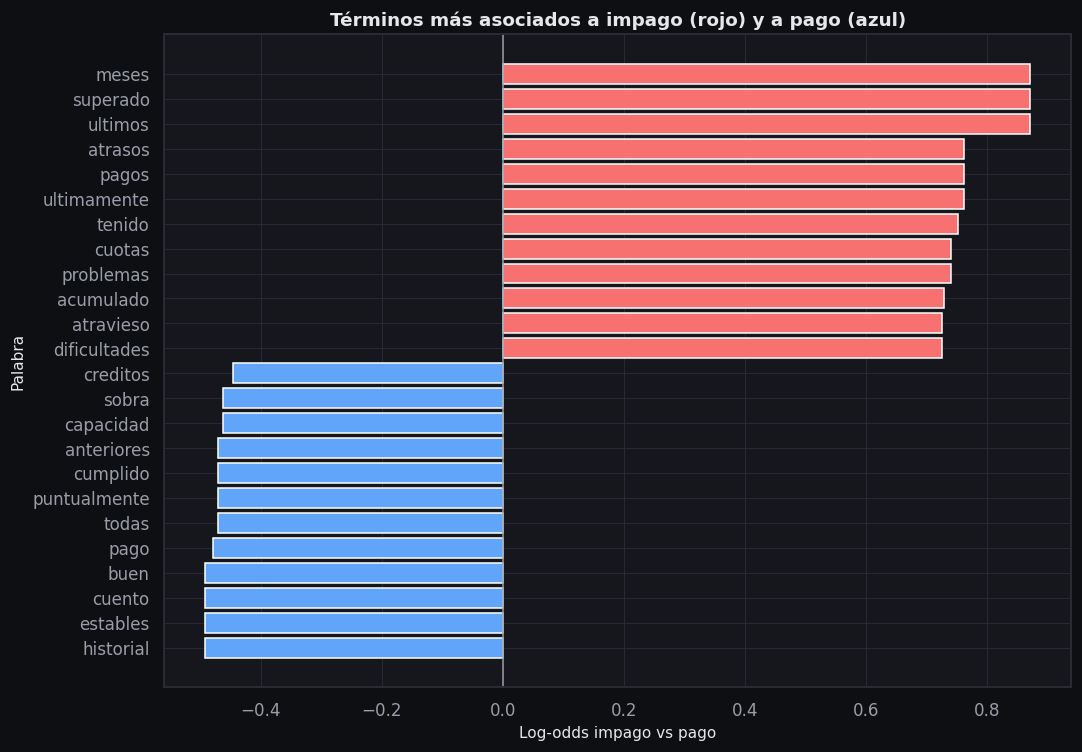

,termino,frec_impago,frec_pago,log_odds
0,meses,297,223,0.8710
1,superado,297,223,0.8710
2,ultimos,297,223,0.8710
3,atrasos,265,222,0.7620
4,pagos,265,222,0.7620
5,ultimamente,265,222,0.7620
6,tenido,543,460,0.7510
7,cuotas,278,238,0.7400
8,problemas,278,238,0.7400
9,acumulado,290,251,0.7290


In [8]:
asociados = terminos_asociados(X_tr[TXT], y_tr, top=12, ngramas=(1, 1))
terminos_impago = asociados.iloc[:12].reset_index(drop=True)
terminos_pago = asociados.iloc[12:].reset_index(drop=True)
graf = pd.concat([terminos_impago, terminos_pago]).sort_values("log_odds")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(graf["termino"], graf["log_odds"],
        color=np.where(graf["log_odds"] > 0, PALETA["impago"], PALETA["pago"]))
ax.axvline(0, color=PALETA["texto_suave"], lw=1)
ax.set(title="Términos más asociados a impago (rojo) y a pago (azul)", xlabel="Log-odds impago vs pago",
       ylabel="Palabra")
plt.show()
figura_front("barras_h", "Términos más asociados a impago y a pago",
             {"categorias": graf["termino"].tolist(),
              "series": [{"nombre": "Log-odds impago vs pago", "valores": graf["log_odds"].round(4).tolist()}]},
             ejes={"x": "Log-odds impago vs pago", "y": "Término"}, clave="terminos_asociados",
             nota="Positivo: más frecuente en impagos; negativo: más frecuente en pagos.",
             opciones={"formato_x": "dec3", "divergente": True})
asociados.round(3)

**Interpretación.** Las palabras más asociadas al impago (rojo) son las de las frases negativas de la
plantilla: *superado / ultimos / meses* (gastos que superan los ingresos), *atrasos*, *problemas*, *cuotas*,
*acumulado*, *dificultades*; las asociadas al pago (azul) son las positivas: *buen historial*, *ingresos
estables*, *cumplido puntualmente*, *capacidad de sobra*. Ninguna palabra es determinante: *atrasos* aparece
265 veces en impagos y 222 en pagos, y *buen* 264 frente a 777. El texto es una señal **ruidosa** del riesgo,
no una regla.

## 2. Línea base NLP: TF-IDF + regresión logística (solo texto)

`build_modelo_texto()` = TF-IDF de unigramas y bigramas (sin stopwords) + regresión logística balanceada.
Para que sus probabilidades sean comparables con el umbral 0,25 se **calibra** (sigmoide, `ensemble=False`),
igual que el modelo de texto que entrena `train.py` y sirve la API en `/predict/text`. El AUC de validación
cruzada no cambia con la calibración (es monótona).

In [9]:
def evaluar(nombre, estimador, Xa, Xb, cv_estimador=None):
    """CV (ROC-AUC) en train, ajuste con todo train y probabilidades en test, con tiempos."""
    t0 = time.perf_counter()
    r = cross_validate(cv_estimador or estimador, Xa, y_tr, cv=CV, scoring="roc_auc", n_jobs=1)
    estimador.fit(Xa, y_tr)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    p = estimador.predict_proba(Xb)[:, 1]
    ms = 1000 * (time.perf_counter() - t0) / len(Xb)
    return {"modelo": nombre, "roc_auc_cv": r["test_score"].mean(), "roc_auc_cv_std": r["test_score"].std(),
            "p": p, "tiempo_s": t_fit, "ms_clasificador": ms, "estimador": estimador}


R = {}
R["TF-IDF + LR"] = evaluar("TF-IDF + LR", calibrado(build_modelo_texto(), cv=3 if FAST else config.CV_FOLDS),
                           X_tr[TXT].fillna(""), X_te[TXT].fillna(""), cv_estimador=build_modelo_texto())
tfidf = R["TF-IDF + LR"]
print(f"AUC CV {tfidf['roc_auc_cv']:.4f} ± {tfidf['roc_auc_cv_std']:.4f} · entrenamiento {tfidf['tiempo_s']:.1f} s · "
      f"inferencia {tfidf['ms_clasificador']:.3f} ms/texto")
pd.DataFrame({"TF-IDF + LR (test)": metricas(y_te, tfidf["p"], UMBRAL)}).T

AUC CV 0.6411 ± 0.0147 · entrenamiento 26.5 s · inferencia 0.211 ms/texto


,roc_auc,pr_auc,ks,brier,accuracy,precision,recall,f1
TF-IDF + LR (test),0.6410,0.4899,0.2677,0.2142,0.4425,0.3760,0.8595,0.5232


## 3. Modelos preentrenados de Hugging Face: inferencia y caché

| Modelo | Tipo | Salida |
|---|---|---|
| `nlptown/bert-base-multilingual-uncased-sentiment` | BERT multilingüe afinado en reseñas (1–5 estrellas) | 5 probabilidades + estrellas esperadas |
| `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` | *encoder* de oraciones (similitud semántica) | vector de 384 dimensiones |
| `datificate/gpt2-small-spanish` | GPT-2 *decoder* en español | promedio del último estado oculto, 768 dimensiones |

Todos corren **localmente en CPU** y son gratuitos (sin APIs de pago). Primero se mide la velocidad de
cada uno sobre una muestra fija de textos (sin caché); luego `features_texto` infiere **solo los textos
únicos** (truncados a 64 *tokens*) y guarda el resultado en `db/processed/nlp_features.parquet` por *hash*
del texto normalizado: las ejecuciones siguientes no recalculan nada.

In [10]:
todos = pd.concat([X_tr[TXT], X_te[TXT]], ignore_index=True)
unicos = todos.map(normalizar).drop_duplicates()
tiempos = na.medir_inferencia(unicos.tolist(), n=32 if FAST else 128)
tiempos["estimado_todos_los_unicos_s"] = (tiempos["ms_por_texto"] * len(unicos) / 1000).round(1)
t0 = time.perf_counter()
feats = na.features_texto(todos)
t_feats = time.perf_counter() - t0
feats_tr = feats.iloc[:len(X_tr)].reset_index(drop=True)
feats_te = feats.iloc[len(X_tr):].reset_index(drop=True)
GPT_USADO = na.cargar_gpt2()[2]
inf = na.ULTIMA_INFERENCIA
print(f"GPT-2 usado: {GPT_USADO}")
print(f"Textos: {len(todos):,} filas · {int(inf['textos_unicos']):,} únicos · {int(inf['textos_nuevos']):,} inferidos ahora "
      f"(el resto, desde la caché) · {t_feats:.1f} s · caché en {ruta(na.CACHE)}")
if inf["textos_nuevos"]:
    print("Inferencia de los nuevos: " + " · ".join(f"{k[:-2]} {v:.1f} s" for k, v in inf.items() if k.endswith("_s")))
tiempos

GPT-2 usado: datificate/gpt2-small-spanish
Textos: 12,000 filas · 4,454 únicos · 0 inferidos ahora (el resto, desde la caché) · 4.3 s · caché en db/processed/nlp_features.parquet


,modelo,id_hugging_face,dimension_salida,carga_s,textos,inferencia_s,ms_por_texto,estimado_todos_los_unicos_s
0,BERT sentimiento,nlptown/bert-base-multilingual-uncased-sentiment,5,46.1900,128,21.3600,166.8600,743.2000
1,Sentence-transformers,sentence-transformers/paraphrase-multilingual-...,384,29.5500,128,10.8700,84.9600,378.4000
2,GPT-2,datificate/gpt2-small-spanish,768,3.5700,128,30.4600,237.9800,"1,060.0000"


## 4. Sentimiento con BERT y su relación con el impago

El modelo de nlptown fue afinado con reseñas de productos: predice de 1 a 5 estrellas. Se usa el **valor
esperado** de las estrellas como puntaje de sentimiento (más estrellas = tono más positivo) y se agrupa en
niveles redondeando al entero más cercano.

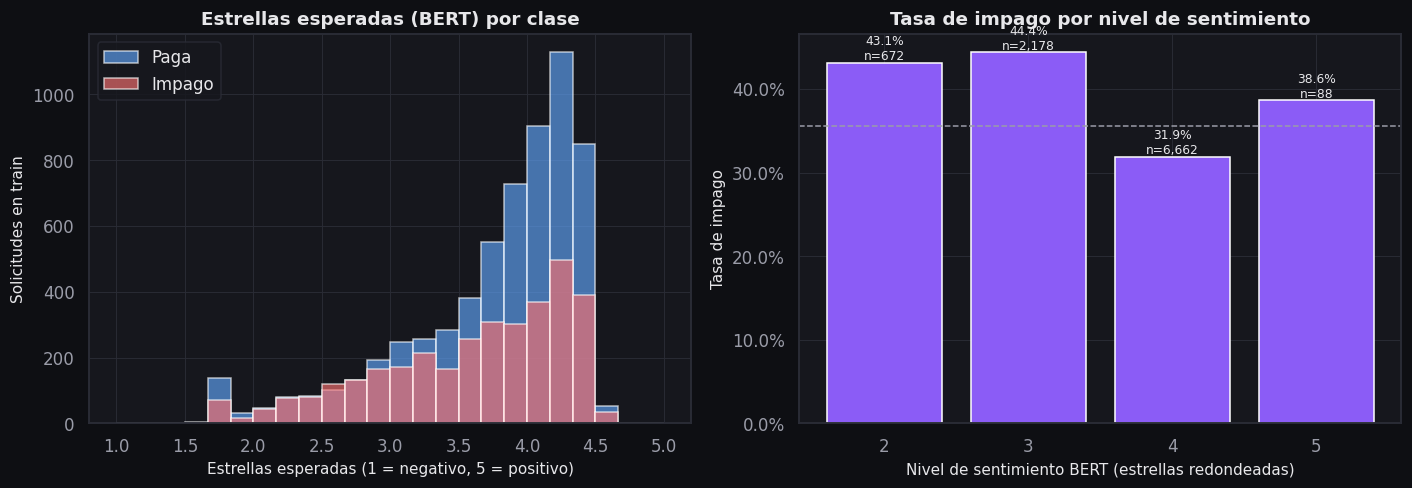

AUC del puntaje de sentimiento por sí solo (menos estrellas = más riesgo), train: 0.5677


,nivel,solicitudes,tasa_impago,estrellas_promedio
0,2,672,0.4315,2.0740
1,3,2178,0.4440,3.0740
2,4,6662,0.3187,4.0710
3,5,88,0.3864,4.5290


In [11]:
sent = pd.DataFrame({"estrellas": feats_tr["bert_estrellas"].to_numpy(), "impago": y_tr})
sent["nivel"] = sent["estrellas"].round().clip(1, 5).astype(int)
tabla_sent = duckdb.sql("""
    SELECT nivel, COUNT(*) AS solicitudes, ROUND(AVG(impago), 4) AS tasa_impago,
           ROUND(AVG(estrellas), 3) AS estrellas_promedio
    FROM sent GROUP BY nivel ORDER BY nivel
""").df()
auc_sent = roc_auc_score(y_tr, -sent["estrellas"])
bordes = np.linspace(1, 5, 25)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
conteos = {}
for clase, nombre, color in [(0, "Paga", PALETA["pago"]), (1, "Impago", PALETA["impago"])]:
    conteos[nombre], _, _ = ax[0].hist(sent.loc[sent["impago"] == clase, "estrellas"], bins=bordes, alpha=0.65,
                                       color=color, label=nombre)
ax[0].set(title="Estrellas esperadas (BERT) por clase", xlabel="Estrellas esperadas (1 = negativo, 5 = positivo)",
          ylabel="Solicitudes en train")
ax[0].legend()
barras = ax[1].bar(tabla_sent["nivel"].astype(str), tabla_sent["tasa_impago"], color=SERIE[3])
ax[1].bar_label(barras, labels=[f"{t:.1%}\nn={n:,}" for t, n in zip(tabla_sent["tasa_impago"], tabla_sent["solicitudes"])],
                fontsize=8, color=PALETA["texto"])
ax[1].axhline(y_tr.mean(), ls="--", color=PALETA["texto_suave"], lw=1)
ax[1].set(title="Tasa de impago por nivel de sentimiento", xlabel="Nivel de sentimiento BERT (estrellas redondeadas)",
          ylabel="Tasa de impago")
ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()
figura_front("histograma", "Estrellas esperadas (BERT) por clase",
             {"bordes": bordes.round(4).tolist(),
              "series": [{"nombre": k, "conteos": [int(c) for c in v]} for k, v in conteos.items()]},
             ejes={"x": "Estrellas esperadas", "y": "Solicitudes en train"}, clave="bert_estrellas_por_clase")
figura_front("barras", "Tasa de impago por nivel de sentimiento BERT",
             {"categorias": tabla_sent["nivel"].astype(str).tolist(),
              "series": [{"nombre": "Tasa de impago", "valores": tabla_sent["tasa_impago"].round(4).tolist()}]},
             ejes={"x": "Nivel de sentimiento (estrellas)", "y": "Tasa de impago"}, clave="impago_por_sentimiento",
             nota=f"Línea de referencia: tasa global {y_tr.mean():.4f}. n por nivel: "
                  + ", ".join(f"{a}: {b}" for a, b in zip(tabla_sent["nivel"], tabla_sent["solicitudes"])),
             opciones={"formato_y": "pct", "referencia_y": round(float(y_tr.mean()), 4)})
print(f"AUC del puntaje de sentimiento por sí solo (menos estrellas = más riesgo), train: {auc_sent:.4f}")
tabla_sent

**Interpretación.** Ninguna solicitud de train cae en el nivel 1 (estrellas esperadas menores que 1,5): el
tono de una solicitud de crédito es moderado. Los niveles 2 y 3 (tono más negativo) tienen una tasa de impago de 43,2 % y 44,4 %, frente a
31,9 % en el nivel 4, que concentra la mayoría de las solicitudes (6.662 de 9.600); el nivel 5 (38,6 %) tiene
solo 88 casos y no es concluyente. Los histogramas de las dos clases se superponen casi por completo: el
puntaje de sentimiento por sí solo apenas ordena el riesgo (AUC 0,568 en train). Es razonable: el modelo se
afinó con reseñas de productos, no con solicitudes de crédito.

Como modelo de predicción, el sentimiento entra a una regresión logística con sus 6 variables
(5 probabilidades + estrellas esperadas).

In [12]:
R["BERT sentimiento + LR"] = evaluar("BERT sentimiento + LR", na.clasificador_embeddings(),
                                     feats_tr[na.COLS_SENTIMIENTO], feats_te[na.COLS_SENTIMIENTO])
r = R["BERT sentimiento + LR"]
print(f"AUC CV {r['roc_auc_cv']:.4f} ± {r['roc_auc_cv_std']:.4f} · AUC test {roc_auc_score(y_te, r['p']):.4f}")

AUC CV 0.5821 ± 0.0108 · AUC test 0.5865


## 5. Embeddings: sentence-transformers frente a GPT-2

Cada vector se estandariza y entra a una regresión logística (sin pesos de clase, para que la probabilidad
sea comparable con el umbral 0,25). Misma validación cruzada en train y mismo test para ambos.

In [13]:
EMB = {"Sentence-transformers + LR": "emb_st", "GPT-2 + LR": "emb_gpt2"}
proy, var_pc = {}, {}
for nombre, col in EMB.items():
    E_tr, E_te = na.matriz(feats_tr, col), na.matriz(feats_te, col)
    R[nombre] = evaluar(nombre, na.clasificador_embeddings(), E_tr, E_te)
    proy[col], var_pc[col] = na.proyeccion_2d(E_tr, y_tr, n_muestra=1500)
ms_emb = tiempos.set_index("modelo")["ms_por_texto"]
comparacion_emb = pd.DataFrame([
    {"modelo": n, "dimension": na.matriz(feats_tr.head(1), c).shape[1],
     "auc_cv": round(R[n]["roc_auc_cv"], 4), "auc_cv_std": round(R[n]["roc_auc_cv_std"], 4),
     "auc_test": round(roc_auc_score(y_te, R[n]["p"]), 4),
     "ms_por_texto_inferencia": ms_emb["Sentence-transformers" if c == "emb_st" else "GPT-2"],
     "varianza_pc1_pc2": round(sum(var_pc[c]), 4)} for n, c in EMB.items()])
comparacion_emb

,modelo,dimension,auc_cv,auc_cv_std,auc_test,ms_por_texto_inferencia,varianza_pc1_pc2
0,Sentence-transformers + LR,384,0.6357,0.0084,0.6407,84.9600,0.2257
1,GPT-2 + LR,768,0.6172,0.0073,0.6332,237.9800,0.3224


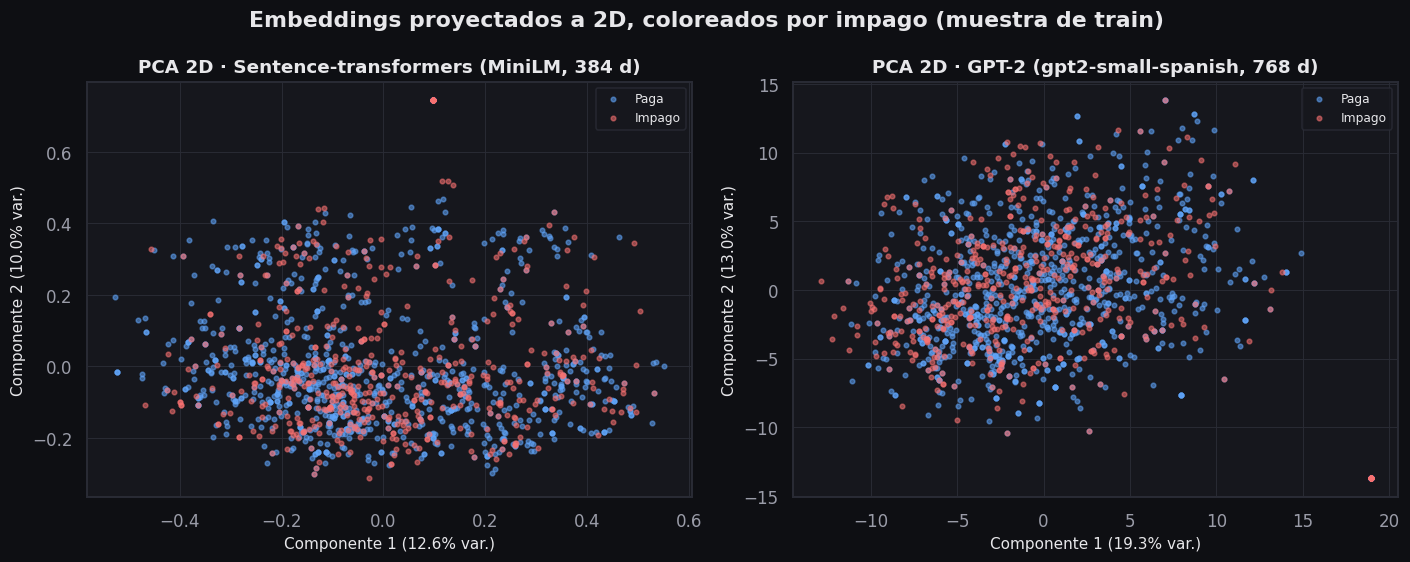

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
titulos = {"emb_st": "Sentence-transformers (MiniLM, 384 d)", "emb_gpt2": f"GPT-2 ({GPT_USADO.split('/')[-1]}, 768 d)"}
for a, col in zip(ax, EMB.values()):
    P = np.asarray(proy[col])
    for clase, nombre, color in [(0, "Paga", PALETA["pago"]), (1, "Impago", PALETA["impago"])]:
        m = P[:, 2] == clase
        a.scatter(P[m, 0], P[m, 1], s=9, alpha=0.55, color=color, label=nombre)
    a.set(title=f"PCA 2D · {titulos[col]}", xlabel=f"Componente 1 ({var_pc[col][0]:.1%} var.)",
          ylabel=f"Componente 2 ({var_pc[col][1]:.1%} var.)")
    a.legend(loc="best", fontsize=8)
    figura_front("dispersion", f"Proyección PCA 2D · {titulos[col]}",
                 {"series": [{"nombre": nombre, "puntos": [[x, y] for x, y, d in proy[col] if d == clase]}
                             for clase, nombre in [(0, "Paga"), (1, "Impago")]]},
                 ejes={"x": f"Componente 1 ({var_pc[col][0]:.1%} var.)", "y": f"Componente 2 ({var_pc[col][1]:.1%} var.)"},
                 clave=f"pca_2d_{col}", nota="Muestra aleatoria de 1.500 solicitudes de train (semilla 42).")
plt.suptitle("Embeddings proyectados a 2D, coloreados por impago (muestra de train)", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación.** En dos dimensiones las nubes de pagos e impagos se superponen en ambos modelos: las dos
primeras componentes explican 22,6 % (sentence-transformers) y 32,2 % (GPT-2) de la varianza y capturan
sobre todo la variación de las frases de propósito y de apertura, no la del riesgo. La separación existe
en más dimensiones: la regresión logística con todos los componentes llega a AUC CV 0,636 con
sentence-transformers y 0,617 con GPT-2. Los vectores del *encoder* entrenado para similitud de oraciones
separan mejor que los de GPT-2, que tiene el doble de dimensiones y es más lento (tabla de tiempos de la
sección 3).

## 6. Modelo NLP de predicción de riesgo (IA3.E1) y modelo combinado

- **Mejor modelo de texto:** el de mayor AUC de validación cruzada en train entre los cuatro anteriores.
- **Modelo combinado:** el mismo pipeline tabular del modelo servido (`build_pipeline` con regresión logística:
  derivadas → capping → imputación/escalado/codificación) **más** el puntaje de sentimiento BERT y 10
  componentes PCA de los *embeddings* del mejor de los dos (por AUC CV). El PCA se ajusta **dentro** del
  pipeline, es decir, solo con la partición de entrenamiento de cada fold.
- **ΔAUC** = AUC(combinado) − AUC(tabular) en test, con IC 95 % por *bootstrap* pareado (mismas filas
  remuestreadas para los dos modelos).

In [15]:
texto_modelos = ["TF-IDF + LR", "BERT sentimiento + LR", "Sentence-transformers + LR", "GPT-2 + LR"]
MEJOR_TEXTO = max(texto_modelos, key=lambda n: R[n]["roc_auc_cv"])
EMB_COMB = max(EMB.items(), key=lambda kv: R[kv[0]]["roc_auc_cv"])[1]
N_PCA = 10
extra_tr, extra_te = na.expandir(feats_tr, [EMB_COMB]), na.expandir(feats_te, [EMB_COMB])
cols_emb = [c for c in extra_tr.columns if c.startswith(EMB_COMB + "_")]
Xc_tr = pd.concat([X_tr.reset_index(drop=True), extra_tr], axis=1)
Xc_te = pd.concat([X_te.reset_index(drop=True), extra_te], axis=1)
LR = catalogo()["Regresión logística"]
TAB = evaluar("Tabular (referencia)", build_pipeline(LR()), X_tr, X_te)
NOMBRE_COMB = f"Combinado: tabular + sentimiento + PCA({N_PCA}) {'ST' if EMB_COMB == 'emb_st' else 'GPT-2'}"
R[NOMBRE_COMB] = evaluar(NOMBRE_COMB, na.build_pipeline_combinado(LR(), ["bert_estrellas"], cols_emb, n_componentes=N_PCA),
                         Xc_tr, Xc_te)
COMB = R[NOMBRE_COMB]
DELTA, deltas_boot = na.delta_auc_bootstrap(y_te, TAB["p"], COMB["p"], n_boot=200 if FAST else 1000)
print(f"Mejor modelo de solo texto (AUC CV): {MEJOR_TEXTO}")
print(f"Embeddings del combinado: {EMB_COMB}")
filas_cmp = {n: {"auc_cv": r["roc_auc_cv"], "auc_cv_std": r["roc_auc_cv_std"], **metricas(y_te, r["p"], UMBRAL)}
             for n, r in [*((k, R[k]) for k in texto_modelos), ("Tabular (referencia)", TAB), (NOMBRE_COMB, COMB)]}
tabla_cmp = pd.DataFrame(filas_cmp).T.sort_values("auc_cv", ascending=False)
tabla_cmp

Mejor modelo de solo texto (AUC CV): TF-IDF + LR
Embeddings del combinado: emb_st


,auc_cv,auc_cv_std,roc_auc,pr_auc,ks,brier,accuracy,precision,recall,f1
Combinado: tabular + sentimiento + PCA(10) ST,0.8582,0.0053,0.8471,0.7695,0.5550,0.1481,0.7354,0.5900,0.8407,0.6934
Tabular (referencia),0.8578,0.0050,0.8459,0.7680,0.5445,0.1488,0.7325,0.5860,0.8454,0.6922
TF-IDF + LR,0.6411,0.0147,0.6410,0.4899,0.2677,0.2142,0.4425,0.3760,0.8595,0.5232
Sentence-transformers + LR,0.6357,0.0084,0.6407,0.4820,0.2564,0.2165,0.5033,0.3986,0.7775,0.5270
GPT-2 + LR,0.6172,0.0073,0.6332,0.4835,0.2401,0.2202,0.5138,0.4014,0.7459,0.5219
BERT sentimiento + LR,0.5821,0.0108,0.5865,0.4205,0.1347,0.2255,0.3558,0.3558,1.0000,0.5249


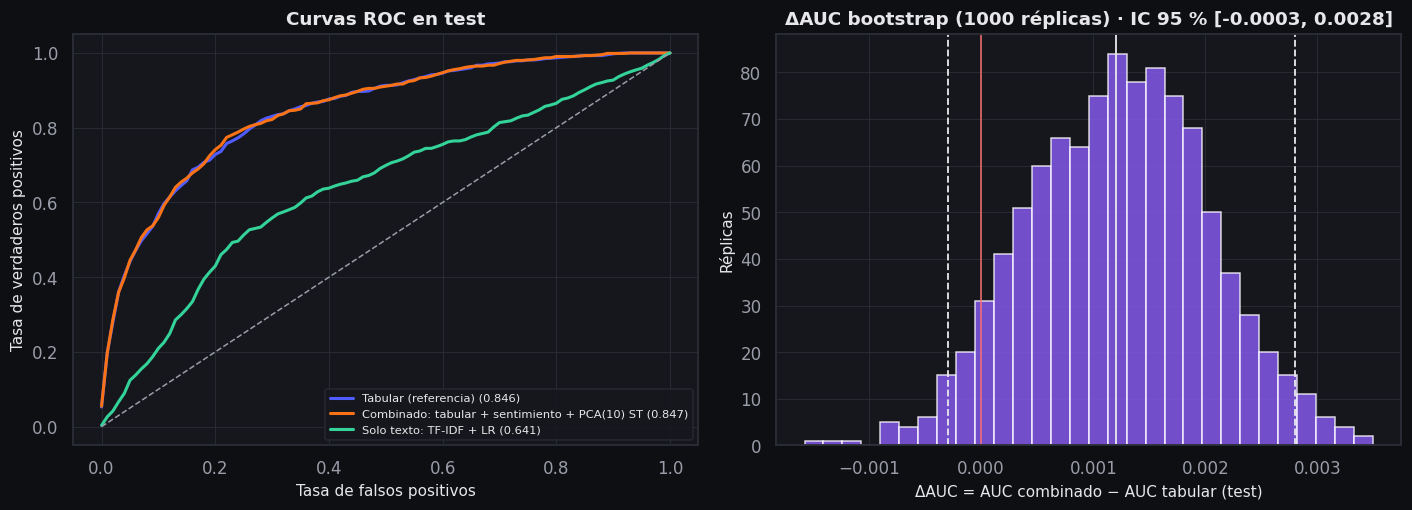

{'valor': 0.0012,
 'ic_inferior': -0.0003,
 'ic_superior': 0.0028,
 'auc_base': 0.8459,
 'auc_nuevo': 0.8471,
 'n_bootstrap': 1000.0,
 'prob_delta_no_positivo': 0.059}

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
roc = {}
for (nombre, p), color in zip([("Tabular (referencia)", TAB["p"]), (NOMBRE_COMB, COMB["p"]),
                               (f"Solo texto: {MEJOR_TEXTO}", R[MEJOR_TEXTO]["p"])], [SERIE[0], SERIE[1], SERIE[2]]):
    roc[nombre] = curvas(y_te, p)
    ax[0].plot(roc[nombre]["fpr"], roc[nombre]["tpr"], color=color, lw=2, label=f"{nombre} ({roc_auc_score(y_te, p):.3f})")
ax[0].plot([0, 1], [0, 1], ls="--", color=PALETA["texto_suave"], lw=1)
ax[0].set(title="Curvas ROC en test", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
ax[0].legend(fontsize=7.5, loc="lower right")
cuentas, bordes_d, _ = ax[1].hist(deltas_boot, bins=30, color=SERIE[3], alpha=0.8)
for v, estilo in [(DELTA["ic_inferior"], "--"), (DELTA["ic_superior"], "--"), (DELTA["valor"], "-")]:
    ax[1].axvline(v, color=PALETA["texto"], ls=estilo, lw=1.2)
ax[1].axvline(0, color=PALETA["alto"], lw=1)
ax[1].set(title=f"ΔAUC bootstrap ({int(DELTA['n_bootstrap'])} réplicas) · IC 95 % "
                f"[{DELTA['ic_inferior']:.4f}, {DELTA['ic_superior']:.4f}]",
          xlabel="ΔAUC = AUC combinado − AUC tabular (test)", ylabel="Réplicas")
plt.tight_layout()
plt.show()
figura_front("curva_roc", "Curvas ROC en test: tabular, combinado y solo texto",
             {"series": [{"nombre": n, "x": c["fpr"], "y": c["tpr"]} for n, c in roc.items()]},
             ejes={"x": "Tasa de falsos positivos", "y": "Tasa de verdaderos positivos"}, clave="roc_combinado_vs_tabular")
figura_front("histograma", "Distribución bootstrap del ΔAUC (combinado − tabular)",
             {"bordes": bordes_d.round(5).tolist(), "series": [{"nombre": "Réplicas", "conteos": [int(c) for c in cuentas]}]},
             ejes={"x": "ΔAUC", "y": "Réplicas"}, clave="delta_auc_bootstrap",
             opciones={"referencias_x": [DELTA["ic_inferior"], DELTA["valor"], DELTA["ic_superior"]]})
figura_front("kpi", "Aporte del texto sobre el modelo tabular (test)",
             {"items": [{"etiqueta": "AUC tabular", "valor": DELTA["auc_base"], "formato": "dec3"},
                        {"etiqueta": "AUC combinado", "valor": DELTA["auc_nuevo"], "formato": "dec3"},
                        {"etiqueta": "ΔAUC", "valor": DELTA["valor"], "formato": "dec3"},
                        {"etiqueta": "IC 95 % inferior", "valor": DELTA["ic_inferior"], "formato": "dec3"},
                        {"etiqueta": "IC 95 % superior", "valor": DELTA["ic_superior"], "formato": "dec3"}]},
             clave="kpi_delta_auc", nota="Aporte sobreestimado: el texto se generó a partir de la probabilidad de impago.")
DELTA

**Interpretación.** Las curvas ROC del modelo tabular y del combinado prácticamente coinciden y ambas quedan
muy por encima del mejor modelo de solo texto. El ΔAUC en test es **+0,0012**, con IC 95 % de −0,0003 a
+0,0028: el intervalo **incluye el cero** (el 5,9 % de las réplicas bootstrap dan ΔAUC ≤ 0). Con esta
representación (sentimiento + 10 componentes PCA) el texto no agrega una mejora demostrable sobre las
variables tabulares: casi todo lo que sabe ya está en ellas.

## 7. Hallazgo y decisión: cómo se construyó el texto y por qué se decide con el modelo tabular

El dataset es sintético (`db/generacion/generar_dataset.py`). Allí la etiqueta se genera con
`prob_default = σ(η)`, donde η combina las variables tabulares **más un ruido** ε ~ N(0; 0,85²) que ninguna
variable observa; y la segunda frase del texto es **negativa** con probabilidad
`p_neg = 0,12 + 0,6 · prob_default`. Es decir, el texto se escribe *mirando la probabilidad real de impago*,
ruido incluido: contiene una señal ruidosa de ε que, por construcción, no está en las variables tabulares.
Por eso conviene medir con cuidado cuánto aporta el texto antes de darle peso en la decisión.

**Prueba empírica.** Si el texto solo repitiera lo que ya dicen las variables tabulares, dentro de un mismo
quintil de riesgo tabular la tasa de impago no debería cambiar según lo que diga el texto. Para resumir el
texto se usa la probabilidad del mejor modelo de solo texto en test, partida en su mediana (texto de riesgo
alto / bajo).

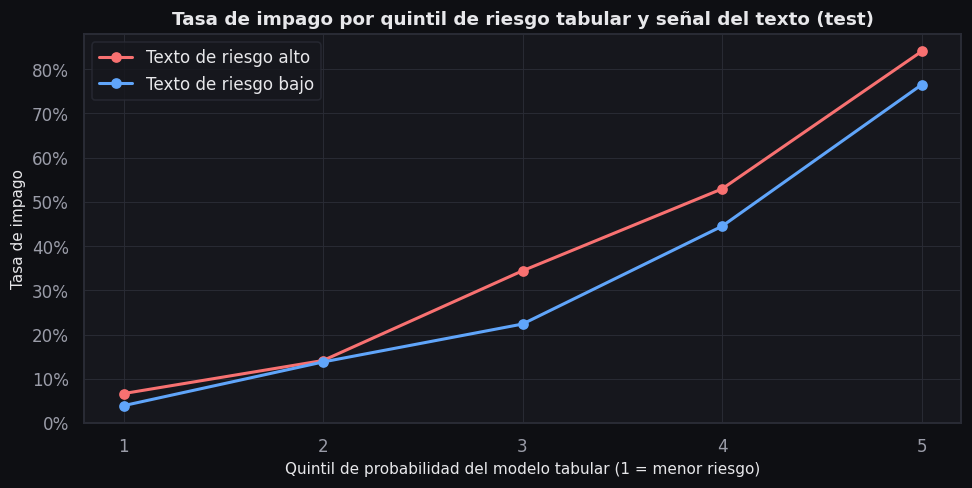

solicitudes             prob_tabular_media             tasa_impago            
texto   riesgo alto riesgo bajo        riesgo alto riesgo bajo riesgo alto riesgo bajo
quintil                                                                               
1          150.0000    330.0000             0.0397      0.0359      0.0667      0.0394
2          205.0000    275.0000             0.1212      0.1216      0.1415      0.1382
3          212.0000    268.0000             0.2689      0.2590      0.3443      0.2239
4          289.0000    191.0000             0.5037      0.4900      0.5294      0.4450
5          344.0000    136.0000             0.8346      0.8158      0.8401      0.7647

In [17]:
p_txt = R[MEJOR_TEXTO]["p"]
estrato = pd.DataFrame({"quintil": pd.qcut(TAB["p"], 5, labels=False) + 1, "p_tabular": TAB["p"],
                        "texto": np.where(p_txt >= np.median(p_txt), "riesgo alto", "riesgo bajo"), "impago": y_te})
por_tono = duckdb.sql("""
    SELECT quintil, texto, COUNT(*) AS solicitudes, ROUND(AVG(p_tabular), 4) AS prob_tabular_media,
           ROUND(AVG(impago), 4) AS tasa_impago
    FROM estrato GROUP BY quintil, texto ORDER BY quintil, texto
""").df()
piv = por_tono.pivot(index="quintil", columns="texto", values="tasa_impago")
fig, ax = plt.subplots(figsize=(9, 4.6))
for grupo, color in [("riesgo alto", PALETA["impago"]), ("riesgo bajo", PALETA["pago"])]:
    ax.plot(piv.index, piv[grupo], marker="o", lw=2, color=color, label=f"Texto de {grupo}")
ax.set(title="Tasa de impago por quintil de riesgo tabular y señal del texto (test)",
       xlabel="Quintil de probabilidad del modelo tabular (1 = menor riesgo)", ylabel="Tasa de impago")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xticks(piv.index)
ax.legend()
plt.show()
figura_front("lineas", "Tasa de impago por quintil de riesgo tabular y señal del texto (test)",
             {"series": [{"nombre": f"Texto de {g}", "x": [int(i) for i in piv.index], "y": piv[g].round(4).tolist()}
                         for g in ("riesgo alto", "riesgo bajo")]},
             ejes={"x": "Quintil de riesgo tabular", "y": "Tasa de impago"}, clave="impago_quintil_texto",
             nota=f"Señal del texto: probabilidad de {MEJOR_TEXTO} partida en su mediana.", opciones={"formato_y": "pct"})
por_tono.pivot(index="quintil", columns="texto", values=["solicitudes", "prob_tabular_media", "tasa_impago"])

**Interpretación.** Dentro de cada quintil la probabilidad tabular media de los dos grupos es casi igual,
pero la tasa de impago es mayor cuando el texto es de riesgo alto: la brecha es clara en los quintiles 1, 3,
4 y 5 (por ejemplo, 34,4 % frente a 22,4 % en el quintil 3 y 84,0 % frente a 76,5 % en el quintil 5) y casi
nula en el 2 (14,2 % frente a 13,8 %). Es decir, el texto contiene información que las variables tabulares no
tienen. Según el generador, esa información proviene de la probabilidad real de impago **con su término de
ruido**, que ninguna variable observa. La decisión de diseño es usar el modelo tabular para decidir y servir
el modelo de texto como análisis complementario (`/predict/text`, entrenado por `train.py`): el combinado no
mejora al tabular de forma demostrable (ΔAUC con IC que incluye el cero) y un modelo con menos piezas es más
explicable, auditable y barato de servir.

## 8. Resultados para la comparación global (pasos 8 y front)

In [18]:
ms_hf = tiempos.set_index("modelo")["ms_por_texto"]
info = {
    "TF-IDF + LR": ("alta", f"TF-IDF 1-2 gramas + LR calibrada; inferencia {tfidf['ms_clasificador']:.3f} ms/texto."),
    "BERT sentimiento + LR": ("media", f"{na.MODELO_SENTIMIENTO}; inferencia BERT {ms_hf['BERT sentimiento']:.1f} ms/texto (CPU)."),
    "Sentence-transformers + LR": ("baja", f"{na.MODELO_EMBEDDINGS}; inferencia {ms_hf['Sentence-transformers']:.1f} ms/texto (CPU)."),
    "GPT-2 + LR": ("baja", f"{GPT_USADO} (promedio del último estado oculto); inferencia {ms_hf['GPT-2']:.1f} ms/texto (CPU)."),
    NOMBRE_COMB: ("media", f"ΔAUC vs tabular {DELTA['valor']:+.4f} (IC 95 % {DELTA['ic_inferior']:+.4f} a "
                           f"{DELTA['ic_superior']:+.4f}); aporte sobreestimado (texto generado con la probabilidad de impago)."),
}
filas = [FilaModelo(modelo=n, familia="nlp", roc_auc_cv=round(float(R[n]["roc_auc_cv"]), 4),
                    roc_auc_cv_std=round(float(R[n]["roc_auc_cv_std"]), 4), test=Metricas(**metricas(y_te, R[n]["p"], UMBRAL)),
                    tiempo_entrenamiento_s=round(R[n]["tiempo_s"], 2), interpretabilidad=info[n][0], notas=info[n][1])
         for n in [*texto_modelos, NOMBRE_COMB]]
redondear = lambda df: [{k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (int, np.integer)) else str(v)))
                         for k, v in fila.items()} for fila in df.to_dict(orient="records")]
res = ResultadosNLP(
    notebook="07_nlp_riesgo.ipynb", umbral_metricas=UMBRAL, modelos=filas,
    curvas={**{n: curvas(y_te, R[n]["p"]) for n in [*texto_modelos, NOMBRE_COMB]}, "Tabular (referencia)": curvas(y_te, TAB["p"])},
    terminos_impago=redondear(terminos_impago), terminos_pago=redondear(terminos_pago),
    sentimiento_vs_impago=redondear(tabla_sent),
    proyeccion_2d={"sentence_transformers": proy["emb_st"], "gpt2": proy["emb_gpt2"]},
    delta_auc={**DELTA, "n_componentes_pca": float(N_PCA)},
)
ruta_res = guardar_resultados(res, "resultados_nlp")
print(f"Escrito {ruta(ruta_res)} · {len(filas)} modelos · caché {ruta(na.CACHE)}")
pd.DataFrame([{"modelo": f.modelo, "auc_cv": f.roc_auc_cv, "auc_test": f.test.roc_auc, "ks": f.test.ks,
               "brier": f.test.brier, "recall": f.test.recall, "f1": f.test.f1,
               "entrenamiento_s": f.tiempo_entrenamiento_s, "interpretabilidad": f.interpretabilidad} for f in filas])

Escrito Back/models/resultados_nlp.json · 5 modelos · caché db/processed/nlp_features.parquet


,modelo,auc_cv,auc_test,ks,brier,recall,f1,entrenamiento_s,interpretabilidad
0,TF-IDF + LR,0.6411,0.6410,0.2677,0.2142,0.8595,0.5232,26.5300,alta
1,BERT sentimiento + LR,0.5821,0.5865,0.1347,0.2255,1.0000,0.5249,0.6700,media
2,Sentence-transformers + LR,0.6357,0.6407,0.2564,0.2165,0.7775,0.5270,32.2700,baja
3,GPT-2 + LR,0.6172,0.6332,0.2401,0.2202,0.7459,0.5219,64.8700,baja
4,Combinado: tabular + sentimiento + PCA(10) ST,0.8582,0.8471,0.5550,0.1481,0.8407,0.6934,4.6100,media


In [19]:
mejor = R[MEJOR_TEXTO]
display(Markdown(
    f"**Resumen calculado.** {int(resumen_textos.loc[0, 'textos_unicos']):,} textos únicos en "
    f"{int(resumen_textos.loc[0, 'solicitudes']):,} solicitudes de train. Mejor modelo de solo texto (AUC CV): "
    f"**{MEJOR_TEXTO}** — AUC CV {mejor['roc_auc_cv']:.4f}, AUC test {roc_auc_score(y_te, mejor['p']):.4f}. "
    f"TF-IDF + LR: AUC test {roc_auc_score(y_te, tfidf['p']):.4f}. "
    f"Sentimiento BERT: tasa de impago de {tabla_sent['tasa_impago'].iloc[0]:.1%} en el nivel {tabla_sent['nivel'].iloc[0]} "
    f"frente a {tabla_sent['tasa_impago'].iloc[-1]:.1%} en el nivel {tabla_sent['nivel'].iloc[-1]} (AUC del puntaje {auc_sent:.4f}). "
    f"Embeddings: ST AUC test {roc_auc_score(y_te, R['Sentence-transformers + LR']['p']):.4f} vs GPT-2 "
    f"{roc_auc_score(y_te, R['GPT-2 + LR']['p']):.4f}. "
    f"Combinado vs tabular: AUC {DELTA['auc_nuevo']:.4f} vs {DELTA['auc_base']:.4f}, **ΔAUC {DELTA['valor']:+.4f}** "
    f"(IC 95 % {DELTA['ic_inferior']:+.4f} a {DELTA['ic_superior']:+.4f}). "
    f"Inferencia en CPU: BERT {ms_hf['BERT sentimiento']:.1f} ms/texto, ST {ms_hf['Sentence-transformers']:.1f} ms/texto, "
    f"GPT-2 {ms_hf['GPT-2']:.1f} ms/texto, TF-IDF {tfidf['ms_clasificador']:.3f} ms/texto."))

**Resumen calculado.** 4,023 textos únicos en 9,600 solicitudes de train. Mejor modelo de solo texto (AUC CV): **TF-IDF + LR** — AUC CV 0.6411, AUC test 0.6410. TF-IDF + LR: AUC test 0.6410. Sentimiento BERT: tasa de impago de 43.1% en el nivel 2 frente a 38.6% en el nivel 5 (AUC del puntaje 0.5677). Embeddings: ST AUC test 0.6407 vs GPT-2 0.6332. Combinado vs tabular: AUC 0.8471 vs 0.8459, **ΔAUC +0.0012** (IC 95 % -0.0003 a +0.0028). Inferencia en CPU: BERT 166.9 ms/texto, ST 85.0 ms/texto, GPT-2 238.0 ms/texto, TF-IDF 0.211 ms/texto.

## Conclusiones

1. **El texto es de plantilla.** Hay 4.023 textos distintos en 9.600 solicitudes de train (4.454 en todo el
   dataset): las frecuencias, los n-gramas con conteos idénticos y los términos asociados reconstruyen las
   frases del generador. Las palabras de impago (*superado*, *atrasos*, *problemas*, *dificultades*) y de pago
   (*buen historial*, *cumplido puntualmente*) aparecen en ambas clases: el texto es una señal ruidosa.
2. **Solo con texto el riesgo se ordena de forma modesta.** AUC de validación cruzada (train) / test:
   TF-IDF + LR 0,641 / 0,641; sentence-transformers 0,636 / 0,641; GPT-2 0,617 / 0,633; sentimiento BERT
   0,582 / 0,587. El modelo tabular llega a 0,846 en test. El mejor modelo de texto por CV es el más simple,
   TF-IDF + LR, que además infiere en 0,21 ms por texto frente a 85–238 ms de los transformers en CPU: es el
   que se sirve en la API (`/predict/text`, entrenado por `train.py`).
3. **El sentimiento de BERT se relaciona débilmente con el impago:** 43,2 % y 44,4 % de impago en los niveles
   2 y 3 frente a 31,9 % en el nivel 4 (AUC del puntaje 0,568). Es un modelo afinado con reseñas de productos:
   otro dominio.
4. **sentence-transformers supera a GPT-2** (AUC CV 0,636 frente a 0,617) con la mitad de dimensiones (384
   frente a 768) y alrededor de un tercio del tiempo de inferencia (85,0 frente a 238,0 ms por texto). Para representar
   oraciones conviene un *encoder* entrenado para similitud más que el promedio de estados de un modelo
   generativo. En 2D (PCA) ninguna de las dos representaciones separa las clases.
5. **Modelo combinado (IA3.E1):** tabular + sentimiento + 10 componentes PCA de sentence-transformers obtiene
   AUC 0,8471 frente a 0,8459 del tabular: **ΔAUC +0,0012, IC 95 % [−0,0003; +0,0028]**. El modelo tabular ya
   captura la señal: la decisión usa el modelo tabular.
6. **Hallazgo y decisión.** El generador escribe la frase negativa con probabilidad 0,12 + 0,6 ·
   `prob_default`; la sección 7 muestra que, a igual riesgo tabular, el texto de riesgo alto tiene más impago en
   casi todos los quintiles. La decisión de diseño: el modelo tabular decide y el texto se sirve como análisis
   complementario en `/predict/text` y en el simulador.
7. **Ingeniería.** Inferir solo los 4.454 textos únicos y cachear por *hash*
   (`db/processed/nlp_features.parquet`) hace que la inferencia costosa ocurra una vez: con los tiempos medidos,
   unos 743 s para BERT, 378 s para sentence-transformers y 1.060 s para GPT-2 en esta CPU; las ejecuciones
   siguientes leen la caché en segundos. Todo corre localmente, con modelos gratuitos y sin APIs de pago.
8. **Operación.** El modelo de texto servido se monitorea como el tabular (estabilidad y calibración), y
   cualquier cambio en su papel pasa por el mismo protocolo de evaluación y champion–challenger.